# 02 — Exploration (block A)

**Question of this block.** What do the data look like? Where, among our 284 cities, is pollution highest, and how are the pollutants related to weather and geography?

Before any clustering or model, we look at the dataset as it is and at the relationships between variables: a model built on data we have not looked at cannot be checked. This notebook does that, in this order:

1. First look at the table
2. Missing values
3. Distributions, and where Milan stands
4. Maps of PM10 and NO₂
5. Correlations between pollution and weather/geography, and the mixing-layer problem
6. The strongest relations, city by city
7. Milan through the year
8. What we pass on to blocks B and C, and open questions
9. The four-line description of every final figure

**Input:** `data/processed/cities.csv`, built and explained in notebook 01. Nothing is modified here: this notebook only looks.

**Output:** seven figures in `figures/` (names starting with `A`), and a list of facts that blocks B and C need.

In [1]:
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Shared style (colours, fonts, source line, maps): the same for the whole project, in src/
sys.path.append("../src")
from style import (apply_style, source, show, BLUE, GREY, INK, INK_2, MUTED, CORRELATION_SCALE,
                   PM10_BREAKS, PM10_LABELS, PM10_COLOURS, NO2_BREAKS, NO2_LABELS, NO2_COLOURS, DOT_EDGE,
                   GROUP_ORDER, GROUP_COLOURS)
from groups import add_groups, add_logs, LOG_VARIABLES, LOG1P_VARIABLES   # shared rules of the project
from maps import draw_europe, to_map
apply_style()

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

cities = pd.read_csv("../data/processed/cities.csv")
print(cities.shape[0], "cities and", cities.shape[1], "columns")

284 cities and 28 columns


## 1. First look at the table

One row per city. To keep the rest of the notebook readable we put the column names into three groups. The same groups are used by blocks B (pollution only) and C (weather and geography only).

In [2]:
# The three groups of variables
POLLUTION = ["pm10_mean", "pm25_mean", "no2_mean", "o3_peaks", "pm10_days_above_50",
             "pm10_winter_summer", "no2_winter_summer", "no2_weekend_drop", "pm25_pm10_ratio"]
WEATHER = ["temperature", "temperature_winter", "diurnal_range", "rain_mm_day", "wind", "wind_winter",
           "humidity", "solar_radiation", "frost_days_year", "mixing_layer_m", "mixing_layer_winter_m"]
GEOGRAPHY = ["altitude", "dist_sea_km", "population", "lat", "lon"]

# Short names with units, used only as labels in the figures
LABELS = {
    "pm10_mean": "PM10 (µg/m³)", "pm25_mean": "PM2.5 (µg/m³)", "no2_mean": "NO₂ (µg/m³)",
    "o3_peaks": "Ozone peaks (µg/m³)", "pm10_days_above_50": "Days PM10 > 50",
    "pm10_winter_summer": "PM10 winter / summer", "no2_winter_summer": "NO₂ winter / summer",
    "no2_weekend_drop": "NO₂ weekend drop (%)", "pm25_pm10_ratio": "PM2.5 / PM10",
    "temperature": "Temperature (°C)", "temperature_winter": "Winter temperature (°C)",
    "diurnal_range": "Day-night range (°C)", "rain_mm_day": "Rain (mm/day)", "wind": "Wind (m/s)",
    "wind_winter": "Winter wind (m/s)", "humidity": "Humidity (%)", "solar_radiation": "Solar radiation (MJ/m²/day)",
    "frost_days_year": "Frost days / year", "mixing_layer_m": "Mixing layer (m, rough)",
    "mixing_layer_winter_m": "Winter mixing layer (m, rough)", "altitude": "Altitude (m)",
    "dist_sea_km": "Distance from sea (km)", "population": "Population", "lat": "Latitude", "lon": "Longitude",
}

show(cities["country"].value_counts().to_frame("cities"))

,cities
country,
IT,57
DE,56
FR,54
ES,35
PL,32
CZ,10
AT,6
BE,6
CH,5


In [3]:
# Milan, the city at the centre of the question
milan = cities[cities["city"].str.startswith("Milano")].iloc[0]
show(milan[POLLUTION].astype(float).to_frame("Milano"))

,Milano
pm10_mean,29.86
pm25_mean,21.89
no2_mean,35.10
o3_peaks,144.01
pm10_days_above_50,50.32
pm10_winter_summer,2.48
no2_winter_summer,2.37
no2_weekend_drop,16.40
pm25_pm10_ratio,0.73


In [4]:
# Summary of every numeric column: count, mean, spread, min, quartiles, max
show(cities[POLLUTION + WEATHER + GEOGRAPHY].describe().T)

,count,mean,std,min,25%,50%,75%,max
pm10_mean,284.00,19.77,5.67,8.47,15.41,18.30,23.50,39.07
pm25_mean,244.00,12.54,4.46,4.28,9.53,11.04,14.58,26.26
no2_mean,284.00,17.74,5.37,6.96,13.73,17.41,21.04,35.10
o3_peaks,284.00,113.20,11.87,81.82,106.50,113.19,118.86,157.03
pm10_days_above_50,284.00,12.38,15.57,0.06,2.59,4.73,15.34,73.19
pm10_winter_summer,284.00,1.35,0.44,0.59,1.07,1.24,1.53,2.98
no2_winter_summer,284.00,1.88,0.47,0.95,1.53,1.78,2.12,3.63
no2_weekend_drop,284.00,20.16,4.66,5.48,17.46,20.23,23.05,39.26
pm25_pm10_ratio,244.00,0.63,0.10,0.26,0.57,0.63,0.70,0.84
temperature,284.00,12.09,3.07,2.82,9.70,11.05,14.31,19.38


> ✅ **CHECKPOINT 1 — table loaded.** 284 cities in 20 countries, 28 columns in three groups: 9 pollution, 11 weather, 5 geography (plus country, city and the target `exceeds_pm10_limit`).

**"Over the limit" in this notebook** always means our **PM10 exceedance indicator**: more than 35 days a year above 50 µg/m³, averaged over the background stations of the city and over 2016–2023 (notebook 01, section 5). It is not a legal compliance check.

## 2. Missing values

Before drawing anything: which columns have holes, **where** are they and **why**? A missing value is a problem when it is not random: if, for example, all the missing values were in the most polluted cities, any analysis that drops them would describe a cleaner Europe than the real one.

### 2.1 How many

`cities.isna()` gives a True/False table of the same size as `cities` (True = missing); `.sum()` counts the True values of each column (True counts as 1). We keep only the columns with at least one missing value.

In [5]:
missing = cities.isna().sum()
show(missing[missing > 0].to_frame("cities with missing value"))

,cities with missing value
pm25_mean,40
pm25_pm10_ratio,40


Only two columns, and they are the same 40 cities: without PM2.5 the PM2.5/PM10 ratio cannot be computed. **Population is complete**: the 12 values that the Eurostat matching had missed were filled in notebook 01 from official sources (Eurostat, Statistik Austria, INSEE).

### 2.2 Where: by country

For each country: how many cities it has, how many of them lack PM2.5, and what share that is. `groupby("country")` splits the table by country; `.size()` counts the rows, `.sum()` on the True/False column counts the missing ones.

In [6]:
no_pm25 = cities["pm25_mean"].isna()
by_country = pd.DataFrame({
    "cities": cities.groupby("country").size(),
    "without PM2.5": no_pm25.groupby(cities["country"]).sum(),
})
by_country["share (%)"] = 100 * by_country["without PM2.5"] / by_country["cities"]
show(by_country[by_country["without PM2.5"] > 0].sort_values("without PM2.5", ascending=False), 0)

,cities,without PM2.5,share (%)
country,,,
ES,35,14,40
DE,56,9,16
CH,5,4,80
IT,57,4,7
PL,32,3,9
LT,2,2,100
FR,54,2,4
HU,3,1,33
PT,5,1,20


Spread over 9 countries. Spain loses 40% of its cities (14 of 35), Switzerland 4 of 5, and Lithuania has no PM2.5 at all (both its cities): for PM2.5, Lithuania would disappear from the analysis.

### 2.3 Why: station by station

The intermediate table `coverage_pm_station_years.csv` has one row per **background station** and year, with the number of valid days. For the 40 cities we look for PM2.5 stations in 2016–2023: either there is none, or there is one with too few days (a year counts only with at least 274 valid days, 75% of the year).

In [7]:
stations = pd.read_csv("../data/interim/coverage_pm_station_years.csv")
pm25_stations = stations[(stations["pollutant"] == "PM2.5") & stations["year"].between(2016, 2023)]

cities_without = cities.loc[no_pm25, ["country", "city"]]
partial = (pm25_stations.merge(cities_without, on=["country", "city"])      # PM2.5 stations of those cities
           .groupby(["country", "city"])
           .agg(stations=("eoi", "nunique"), years_with_data=("year", "nunique"), max_valid_days=("valid_days", "max"))
           .reset_index())

print("Cities without PM2.5:", len(cities_without))
print("  - no background station measuring PM2.5:", len(cities_without) - len(partial))
print("  - a station exists, but with too few valid days:", len(partial))
show(partial.sort_values("max_valid_days", ascending=False))

Cities without PM2.5: 40
  - no background station measuring PM2.5: 32
  - a station exists, but with too few valid days: 8


,country,city,stations,years_with_data,max_valid_days
1,DE,Köln,1,8,183
3,ES,Lorca,1,3,181
0,DE,Gera,1,1,165
4,ES,Palma de Mallorca,1,8,130
5,ES,Pamplona/Iruña,1,8,120
2,ES,Logroño,1,8,117
6,ES,Santander,1,8,112
7,HU,Debrecen,1,8,60


- **32 cities: the measurement does not exist.** No background station measures PM2.5 there. The EEA is already the official collection of what national agencies measure, so there is no other official source to search.
- **8 cities: a station exists but samples rarely**, at most 60–183 days a year, probably one sample every 2–3 days (common for PM2.5 measured by weighing filters). We could lower the threshold for PM2.5 only, but means on few days are less comparable, and the most important cities (below) would stay without PM2.5 anyway.

### 2.4 Are the cities without PM2.5 different?

If the missing cities were all clean, or all polluted, dropping them would bias the results. We compare the two groups.

In [8]:
group = no_pm25.map({False: "with PM2.5", True: "without PM2.5"}).rename("group")
compare = cities.groupby(group).agg(cities=("city", "size"),
                                    median_pm10=("pm10_mean", "median"),
                                    over_pm10_limit=("exceeds_pm10_limit", "sum"))
show(compare, 1)

,cities,median_pm10,over_pm10_limit
group,,,
with PM2.5,244,18.4,27
without PM2.5,40,17.9,3


In [9]:
# The most polluted cities without PM2.5
show(cities[no_pm25].nlargest(5, "pm10_mean")[["country", "city", "pm10_mean", "pm10_days_above_50"]], 1)

,country,city,pm10_mean,pm10_days_above_50
263,PL,Rybnik,39.1,73.2
271,PL,Zabrze,35.4,64.4
191,IT,Carpi,28.9,42.6
95,ES,Guadalajara,28.3,19.6
111,ES,Talavera de la Reina,25.9,15.8


On average the two groups are similar (median PM10 18.4 against 17.9), so the missing values are not "all the clean cities" or "all the dirty ones". But the list contains **Rybnik and Zabrze, the two cities with the highest PM10 of our 284**, and 3 of the 30 cities over the limit. Dropping the 40 cities would remove exactly the extreme cases the clustering must see.

### 2.5 How to handle them

PM2.5 and PM10 are strongly related (Spearman correlation below: a correlation computed on the ranks of the cities, explained in section 5.1), which matters for option 2.

In [10]:
print("Spearman PM10 - PM2.5 (244 cities with both):",
      round(cities["pm10_mean"].corr(cities["pm25_mean"], method="spearman"), 2))

Spearman PM10 - PM2.5 (244 cities with both): 0.83


<table style="margin-left:0; margin-right:auto">
<tr><th style="text-align:left">Option</th><th style="text-align:left">What it does</th><th style="text-align:left">Problem</th><th style="text-align:left">Verdict</th></tr>
<tr><td style="text-align:left">1. Drop the 40 cities</td><td style="text-align:left">Keep only the 244 cities with PM2.5</td><td style="text-align:left">Loses Rybnik and Zabrze, the two most polluted cities, and 14 of the 35 Spanish cities: the sample becomes biased</td><td style="text-align:left">✘</td></tr>
<tr><td style="text-align:left">2. Drop the two PM2.5 columns</td><td style="text-align:left">Cluster the 284 cities on the other 7 pollution variables</td><td style="text-align:left">Loses the fine-particle information. Small loss for PM2.5 itself (strongly tied to PM10); real loss for the PM2.5/PM10 ratio</td><td style="text-align:left">✔ main choice</td></tr>
<tr><td style="text-align:left">3. Estimate (impute) PM2.5</td><td style="text-align:left">Fill with PM10 × the median ratio (0.64)</td><td style="text-align:left">Invents values: the 40 cities would all get the same ratio, so the ratio says nothing about them; Rybnik and Zabrze (coal) probably have a higher one</td><td style="text-align:left">✘ for the analysis</td></tr>
<tr><td style="text-align:left">4. Do both and compare</td><td style="text-align:left">Clustering with option 2 (284 cities) and with option 1 (244 cities, all 9 variables)</td><td style="text-align:left">Twice the work</td><td style="text-align:left">✔ as a robustness check (agreement measured with ARI)</td></tr>
</table>

**Recommendation for block B:** cluster the 284 cities **without the two PM2.5 columns** (option 2), and as a check repeat the clustering on the 244 complete cities with all 9 variables (option 4). If the groups agree, the choice did not change the result; if not, it is worth reporting. Block C is not affected: it does not use pollution variables as predictors.

> ✅ **CHECKPOINT 2 — missing values understood.** Only PM2.5 and PM2.5/PM10 are missing (40 cities: 32 without any measurement, 8 with too few days). They are not random enough to drop: Rybnik and Zabrze are among them. Everything else is complete.

## 3. Distributions, and where Milan stands

### 3.1 One histogram per variable

One histogram per variable; the **blue line is Milan**. In the title, the **skewness**: a number computed from the data (not a parameter we choose) that measures how lopsided the distribution is. 0 means symmetric; above about 1 means a long tail to the right (a few cities with very high values). Strongly skewed variables may need a logarithm before clustering (block B) or modelling (block C), otherwise a few extreme cities dominate. Population is drawn on a logarithmic axis, otherwise all cities would sit in the first bar.

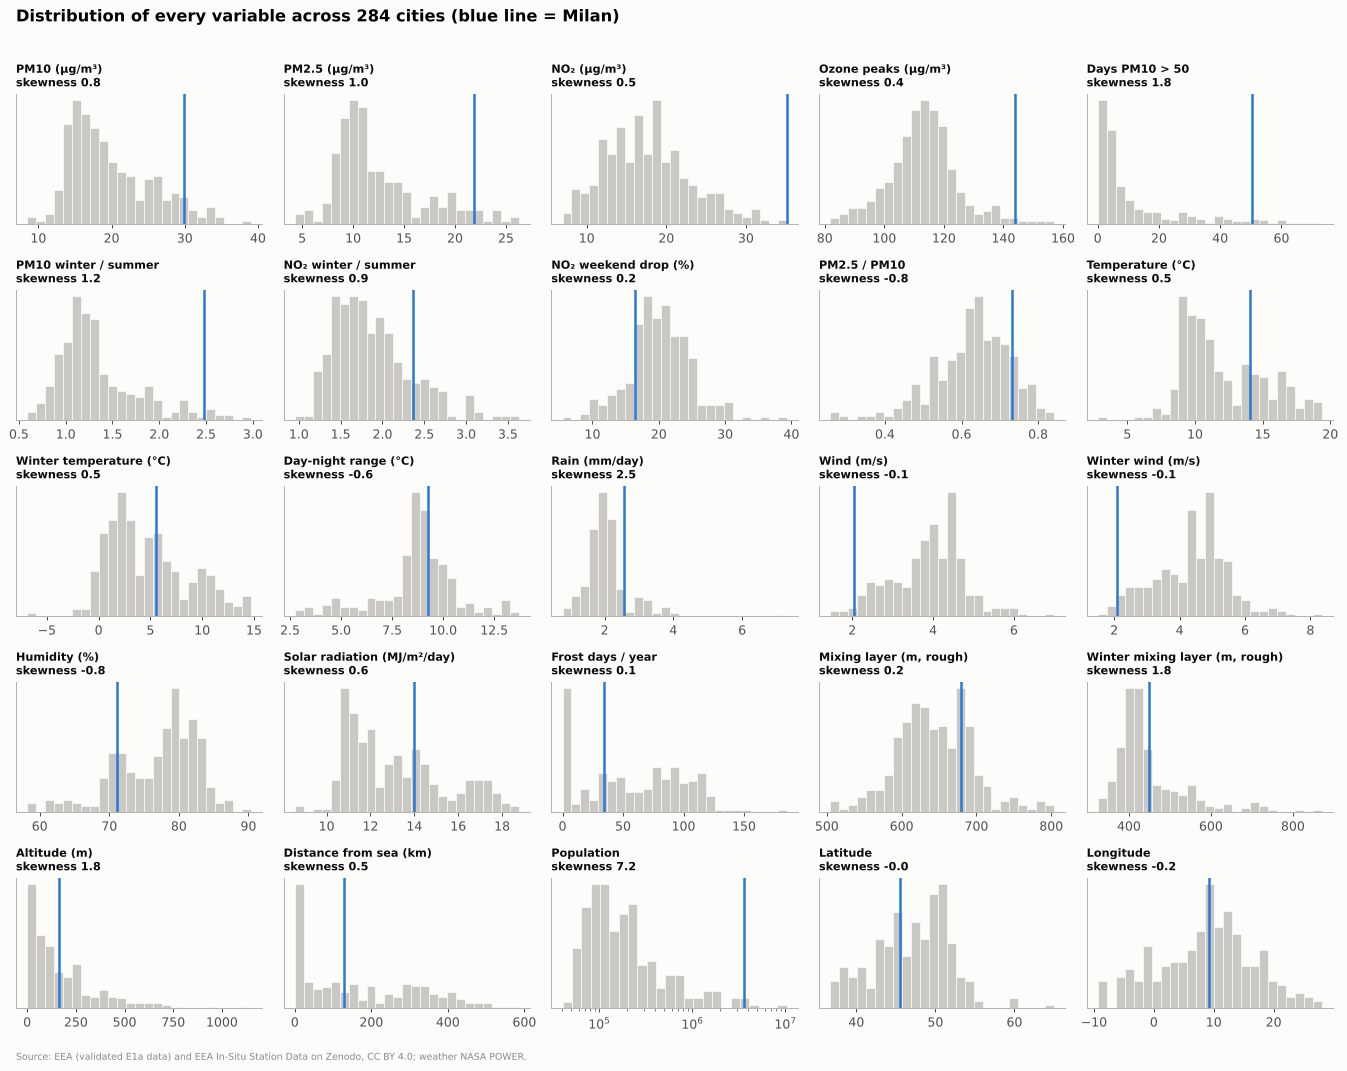

In [11]:
variables = POLLUTION + WEATHER + GEOGRAPHY
fig, axes = plt.subplots(5, 5, figsize=(15, 12))

for ax, var in zip(axes.flat, variables):
    values = cities[var].dropna()
    if var == "population":                                          # very skewed: logarithmic bins and axis
        bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 25)
        ax.set_xscale("log")
    else:
        bins = 25
    ax.hist(values, bins=bins, color=GREY, edgecolor="white", linewidth=0.5)
    ax.axvline(milan[var], color=BLUE, linewidth=2)                  # Milan
    ax.set_title(f"{LABELS[var]}\nskewness {values.skew():.1f}", fontsize=9, loc="left")
    ax.set_yticks([])                                                # counts are not important here
    ax.grid(False)

fig.suptitle("Distribution of every variable across 284 cities (blue line = Milan)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0.02, 1, 0.97))
source(fig)

In [12]:
# Which variables are strongly skewed?
skewness = cities[variables].skew()
skewed = skewness[skewness.abs() > 1].sort_values(ascending=False)
show(skewed.to_frame("skewness"))

,skewness
population,7.18
rain_mm_day,2.51
pm10_days_above_50,1.84
mixing_layer_winter_m,1.82
altitude,1.78
pm10_winter_summer,1.22
pm25_mean,1.03


### 3.4 Decision: logarithms

**Why.** k-means and PCA (block B) measure distances between cities, and logistic regression (block C) draws straight lines in the space of the variables: with a long right tail, a few extreme cities dominate both. The logarithm compresses the tail. A random forest and the Spearman correlation do not need it, because they only use the *order* of the values, and the logarithm does not change the order.

**Which.** The variables with skewness above 1 for which the logarithm really helps (check below): population, rain, days PM10 > 50, PM10 winter/summer (a ratio: on a log scale "twice" and "half" become symmetric), and altitude with `log(1 + x)`, because one city is at 0 m and log(0) does not exist. **Not** transformed: the winter mixing layer (the logarithm helps little, 1.8 → 1.3, and it is a weak, rough variable) and PM2.5 (dropped from the clustering anyway). The rule is in `src/groups.py` (`add_logs`), so blocks B and C apply exactly the same transformation.

In [13]:
logged = add_logs(cities)
check = pd.DataFrame({
    "skewness before": cities[LOG_VARIABLES + LOG1P_VARIABLES].skew(),
    "skewness after log": [logged["log_" + v].skew() for v in LOG_VARIABLES + LOG1P_VARIABLES],
})
show(check)

,skewness before,skewness after log
population,7.18,1.24
rain_mm_day,2.51,0.33
pm10_days_above_50,1.84,0.12
pm10_winter_summer,1.22,0.43
altitude,1.78,-0.67


**What we see.**
- **Population** is extremely skewed (a few metropolises, many small cities): use its logarithm.
- Among pollution variables, **PM10 days above 50**, **PM10 winter/summer** and **PM2.5** have long right tails: a group of cities, mostly in the Po Valley and in Poland, is far above the rest.
- Rain, altitude and the winter mixing layer are skewed too (a few very rainy or mountain cities).

### 3.2 Does the shape depend on the bins?

A histogram depends on the width of its bins: a shape can appear or disappear when the bins change, so we trust a shape only if it survives several bin widths. A check on PM10 with 10, 25 and 50 bins:

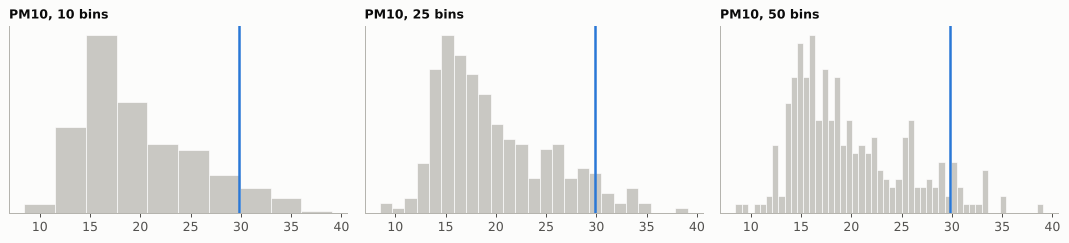

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=False)
for ax, n_bins in zip(axes, [10, 25, 50]):
    ax.hist(cities["pm10_mean"], bins=n_bins, color=GREY, edgecolor="white", linewidth=0.5)
    ax.axvline(milan["pm10_mean"], color=BLUE, linewidth=2)
    ax.set_title(f"PM10, {n_bins} bins", fontsize=10)
    ax.set_yticks([]); ax.grid(False)
fig.tight_layout()

The main shape survives in all three: a peak around 15–18 µg/m³ and a long tail to the right. The small bumps in the tail appear and disappear with the bins: they are noise, not structure. 25 bins is a reasonable middle.

### 3.3 Is this the right way to show Milan?

**What is right.** Milan is a single saturated colour against a grey context (a saturated colour draws the eye only if everything else is neutral), and the panels are small multiples of the same kind of chart.

**What is not right, for showing Milan:**
- **25 panels are far beyond working memory**, which holds about 4 chunks (Cowan, 2001). The grid is a tool to *check* the data, not a figure for the presentation.
- To see whether Milan is high or low, the eye must read **25 different axes with 25 different units**: there is no common scale. Comparing positions along a **common scale** is the most accurate judgement (Cleveland and McGill, 1984).
- The question "where does Milan stand?" is a **comparison across variables**; the histograms answer another question, "what shape does each variable have?".

**Better: one dot plot on a common scale.** For each variable we compute Milan's **percentile rank**: Milan's rank among the cities that have a value, divided by their number (close to 0 = the lowest, 100 = the highest). The denominator is **284 cities, except PM2.5 and PM2.5/PM10, which have 244**. Every variable then lives on the same 0–100 axis, and Milan becomes one dot per row. Choices: rows **sorted by percentile** (order carries meaning, never alphabetical); the grey band marks the middle 50% of cities (the "normal" range) and the tick the median; **direct labels** with Milan's real value and unit, so no legend is needed; horizontal labels; a single highlight colour. Latitude and longitude are left out: "higher" means nothing for them.

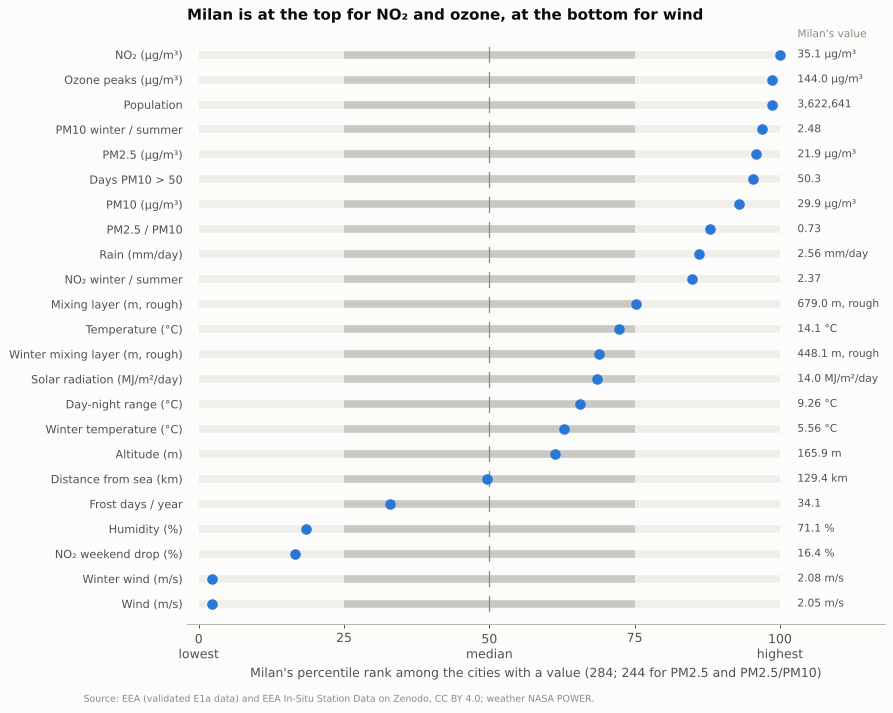

In [15]:
profile_vars = POLLUTION + WEATHER + ["altitude", "dist_sea_km", "population"]

# Milan's percentile rank: rank among the cities with a value (284, or 244 for PM2.5), divided by their number, times 100
percentile = pd.Series({v: cities[v].rank(pct=True)[milan.name] * 100 for v in profile_vars}).sort_values()

def as_text(var, value):
    # Milan's real value, with the unit taken from the label, e.g. "35.1 µg/m³"
    unit = LABELS[var].split("(")[-1].rstrip(")") if "(" in LABELS[var] else ""
    number = f"{value:,.0f}" if abs(value) >= 1000 else f"{value:.2f}" if abs(value) < 10 else f"{value:.1f}"
    return f"{number} {unit}".strip()

fig, ax = plt.subplots(figsize=(10, 8.5))
for row, (var, pct) in enumerate(percentile.items()):
    ax.plot([0, 100], [row, row], color="#efeeeb", linewidth=6, solid_capstyle="butt", zorder=1)   # 0-100 track
    ax.plot([25, 75], [row, row], color=GREY, linewidth=6, solid_capstyle="butt", zorder=2)        # middle 50%
    ax.plot([50, 50], [row - 0.3, row + 0.3], color=MUTED, linewidth=1, zorder=3)                 # median
    ax.scatter(pct, row, s=55, color=BLUE, zorder=4)                                              # Milan
    ax.text(103, row, as_text(var, milan[var]), va="center", fontsize=8.5, color=INK_2)

ax.set_yticks(range(len(percentile)), [LABELS[v] for v in percentile.index], fontsize=9)
ax.set_xticks([0, 25, 50, 75, 100], ["0\nlowest", "25", "50\nmedian", "75", "100\nhighest"])
ax.set_xlim(-2, 118)
ax.set_ylim(-0.8, len(percentile) - 0.2)
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.text(103, len(percentile) - 0.3, "Milan's value", fontsize=8.5, color=MUTED)
ax.set_xlabel("Milan's percentile rank among the cities with a value (284; 244 for PM2.5 and PM2.5/PM10)")
ax.set_title("Milan is at the top for NO₂ and ozone, at the bottom for wind", pad=12)
source(fig)
fig.savefig("../figures/A5_milan_percentiles.png", bbox_inches="tight")

**What we see,** in one look instead of 25: Milan is at the very top for **NO₂** (the highest of all), ozone peaks, PM10 winter/summer, days above 50 and population; at the very bottom for **wind** and winter wind (percentile rank about 2); in the normal range for altitude, distance from the sea, frost days and the mixing layer. The grid in 3.1 stays as the data check; this figure is the one to use in the presentation.

> ✅ **CHECKPOINT 3 — distributions checked.** Strongly skewed (consider a logarithm): population, rain, days PM10 > 50, winter mixing layer, altitude, PM10 winter/summer, PM2.5. Shapes do not depend on the bins. Milan stands out for NO₂, ozone, winter smog and lack of wind (figure A5).

## 4. Where is pollution highest? Maps of PM10 and NO₂

### 4.1 Design choices

- **Projection: Lambert azimuthal equal-area (EPSG:3035).** It is the projection the European Environment Agency uses for its maps of Europe, and it is *equal-area*: every country keeps its true size relative to the others. A plain longitude/latitude plot would stretch northern Europe sideways. The conversion is a short formula in `src/maps.py`, so no extra library is needed.
- **Basemap:** land in light grey, sea white, thin white borders (Natural Earth, public domain). The context is there but quiet: the data are the only coloured marks.
- **One dot per city, all the same size.** Position says *where*; size carries no data, because area is a weak channel (readers underestimate large areas) and large bubbles would hide each other in the dense Po Valley.
- **Classes, not a continuous scale.** A continuous shade keeps the order of every city but no reader can read a value from it; with classes the reader matches a dot to the legend (the classed/unclassed trade-off). The breaks are **reference values, declared** (references for reading the map, not a compliance check): for PM10, 15 µg/m³ is the WHO 2021 guideline and 20 the new EU annual limit from 2030; for NO₂, 10 and 20 are the same two references.
- **Palette: ColorBrewer YlOrRd** (colorbrewer2.org): sequential, light = clean, dark = polluted, colour-blind safe and readable in print. The warm "alarm" colours are a deliberate choice for a pollution map; the lightest class has a grey outline so it stays visible on the land.
- **Two maps side by side, same projection and extent**: PM10 and NO₂, to compare the two kinds of smog. Milan is circled and labelled directly.

All these parameters (colours, breaks, labels) are stored in `src/style.py`, so every map of the project uses the same ones.

### 4.2 Alternatives considered

<table style="margin-left:0; margin-right:auto">
<tr><th style="text-align:left">Alternative</th><th style="text-align:left">Why not (or why yes)</th></tr>
<tr><td style="text-align:left">Plain longitude/latitude plot</td><td style="text-align:left">Not equal-area: northern Europe is stretched sideways, and it needed a manual correction of the proportions</td></tr>
<tr><td style="text-align:left">Continuous colour scale</td><td style="text-align:left">Preserves the order of every city, but nobody can read a value from a shade (colour intensity is read only roughly)</td></tr>
<tr><td style="text-align:left">Bubbles sized by PM10</td><td style="text-align:left">Area is a weak channel (large areas are underestimated) and big bubbles hide their neighbours in the dense Po Valley</td></tr>
<tr><td style="text-align:left">Choropleth of regions</td><td style="text-align:left">Our data are cities, not regions: a regional mean would invent values for the land between cities</td></tr>
<tr><td style="text-align:left">Heat map / density surface</td><td style="text-align:left">It shows where there are many stations, not where pollution is high</td></tr>
<tr><td style="text-align:left"><b>Chosen: dots on an equal-area map, 5 classes with reference breaks, two maps side by side</b></td><td style="text-align:left">Position on the map carries <i>where</i>, the class colour carries <i>how much</i>, readable against the legend. PM10 and NO₂ next to each other show the two kinds of smog at a glance</td></tr>
</table>

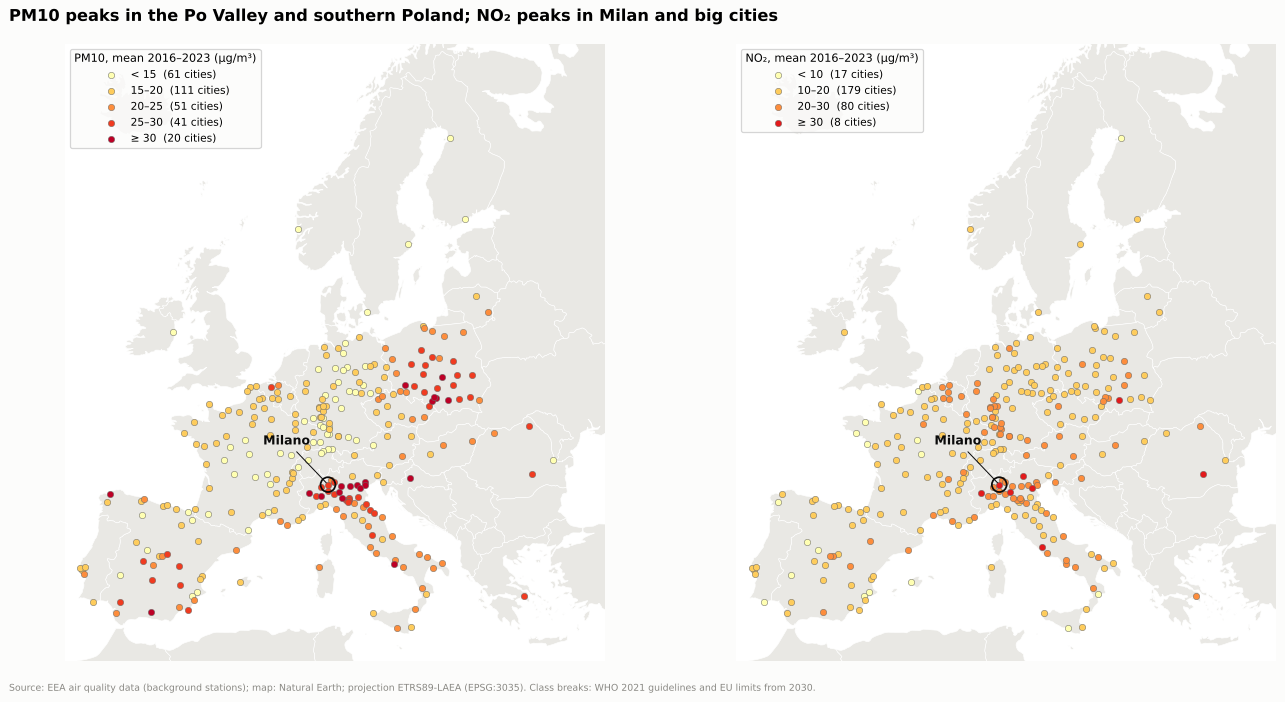

In [16]:
x, y = to_map(cities["lon"], cities["lat"])            # longitude/latitude -> map coordinates in metres
mx, my = to_map(milan["lon"], milan["lat"])

fig, axes = plt.subplots(1, 2, figsize=(15, 7.8))
maps = [(axes[0], "pm10_mean", PM10_BREAKS, PM10_COLOURS, PM10_LABELS, "PM10, mean 2016–2023 (µg/m³)"),
        (axes[1], "no2_mean", NO2_BREAKS, NO2_COLOURS, NO2_LABELS, "NO₂, mean 2016–2023 (µg/m³)")]

for ax, var, breaks, colours, labels, title in maps:
    draw_europe(ax)
    classes = np.digitize(cities[var], breaks)         # class of each city: 0 = lowest ... len(breaks) = highest
    order = np.argsort(classes)                        # draw the dark classes last, on top
    for k in range(len(colours)):
        chosen = order[classes[order] == k]
        ax.scatter(x[chosen], y[chosen], s=26, color=colours[k], edgecolor=DOT_EDGE, linewidth=0.4,
                   zorder=2, label=f"{labels[k]}  ({len(chosen)} cities)")
    ax.scatter(mx, my, s=140, facecolor="none", edgecolor=INK, linewidth=1.4, zorder=3)     # ring on Milan
    ax.annotate("Milano", (mx, my), xytext=(mx - 420_000, my + 260_000), fontsize=10, fontweight="bold", color=INK,
                arrowprops=dict(arrowstyle="-", color=INK, linewidth=0.8))      # label with a short line (map metres)
    ax.legend(title=title, loc="upper left", frameon=True, fontsize=8.5, title_fontsize=9)

fig.suptitle("PM10 peaks in the Po Valley and southern Poland; NO₂ peaks in Milan and big cities",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.05, wspace=0.03)
source(fig, "Source: EEA air quality data (background stations); map: Natural Earth; projection ETRS89-LAEA (EPSG:3035). "
            "Class breaks: WHO 2021 guidelines and EU limits from 2030.")
fig.savefig("../figures/A1_pm10_no2_maps.png", bbox_inches="tight")

In [17]:
# The 15 cities with the highest PM10
show(cities.nlargest(15, "pm10_mean")[["country", "city", "pm10_mean", "no2_mean", "pm10_days_above_50"]], 1)

,country,city,pm10_mean,no2_mean,pm10_days_above_50
263,PL,Rybnik,39.1,20.9,73.2
271,PL,Zabrze,35.4,20.6,64.4
195,IT,Cremona,35.0,30.9,68.1
209,IT,Padova,33.5,30.2,66.9
258,PL,Piotrków Trybunalski,33.3,18.6,54.0
189,IT,Brescia,33.3,27.9,60.2
250,PL,Katowice,33.2,26.5,49.8
94,ES,Granada,33.0,21.1,42.7
253,PL,Kraków,32.9,30.1,55.2
236,IT,Vicenza,32.1,27.9,60.8


**What we see.** Two hot spots for PM10: **southern Poland** (Rybnik, Zabrze, Katowice, Kraków: coal for heating and industry) and the **Po Valley** (Cremona, Padova, Brescia, Vicenza, Verona…). The NO₂ map is different: the dark dots are the big cities and the Po Valley, while the Polish cities, so dark for PM10, are only medium. Milan is not at the very top for PM10 (29.9), but it is first of the 284 cities for **NO₂** (35.1). Two different kinds of pollution, which is exactly what block B will look at.

> ✅ **CHECKPOINT 4 — maps done.** PM10: Po Valley and southern Poland. NO₂: big cities, Po Valley, Milan first. Figure A1, with parameters saved in `src/style.py` and `src/maps.py`.

## 5. How is pollution related to weather and geography?

### 5.1 What Spearman correlation is

A correlation is a number from **−1 to +1** that says whether two variables move together across the cities:
- **+1**: when one is higher, the other is always higher too;
- **−1**: when one is higher, the other is always lower;
- **0**: no relation.

The usual one (Pearson) measures how well the points lie on a **straight line**, and a few extreme cities can push it up or down a lot. **Spearman** first replaces each value with its **rank** (1 = the lowest city, 284 = the highest) and then computes the same thing on the ranks. So it asks a simpler question: *do the cities that rank high on one variable also rank high on the other?* It works for any relation that always goes in the same direction (even a curved one), and an extreme city counts only as "first in the ranking", not as a huge number. That is why we use it here, with many skewed variables.

> **Note — why Spearman, in one line:** several variables are strongly skewed, and ranks are not driven by a few extreme cities; it also catches relations that always go the same way but are not straight lines. It is the correlation counterpart of the rank tests used later (Kruskal–Wallis in section 6 and in block B): ranks instead of values, for skewed data.

Two warnings. A correlation is **not a cause** (two variables can move together because of a third one: section 5.3 is an example). And it summarises **all of Europe**: a relation can be weak overall and strong inside one region.

### 5.2 The correlation heatmap

**Are the colours right?** In a correlation **zero has a meaning** ("no relation"), so a *diverging* scale with a neutral middle is correct. The usual red–blue scale is not a good choice here: red reads as "bad" or "danger": a reader could think that red cells are the worse ones. A correlation has no good or bad sign: +0.5 between humidity and NO₂ would be no "better" or "worse" than −0.5. So we use **purple–orange** (ColorBrewer PuOr): diverging, colour-blind safe, and neither colour suggests a judgement. Purple = negative, white = zero, orange = positive; the ends of the colour bar say it in words. Rows are sorted by their correlation with PM10.

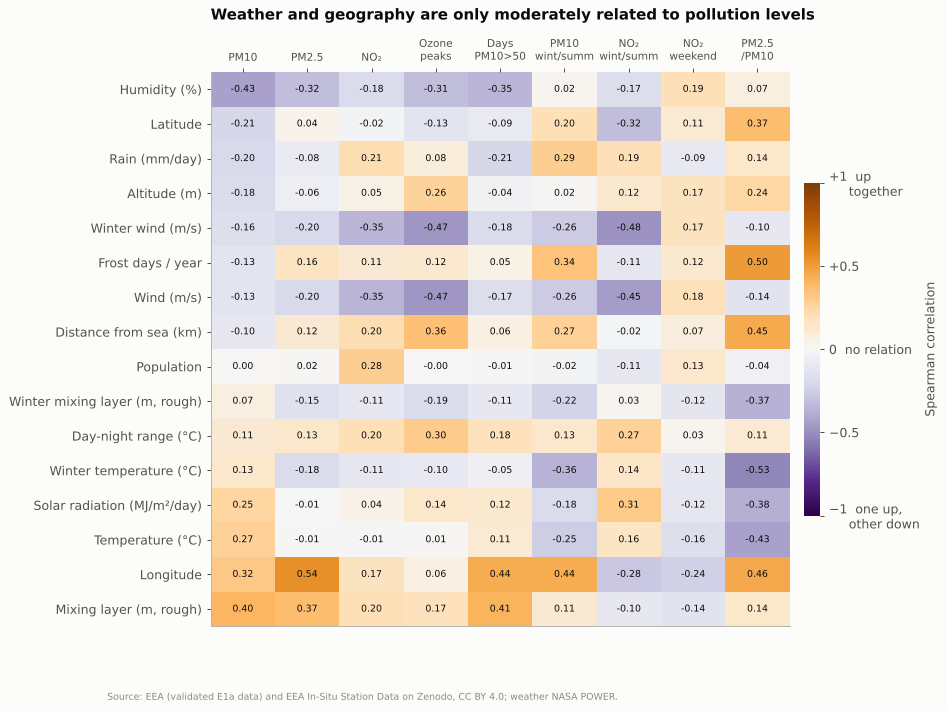

In [18]:
EXTERNAL = WEATHER + GEOGRAPHY
corr = cities[POLLUTION + EXTERNAL].corr(method="spearman").loc[EXTERNAL, POLLUTION]
corr = corr.sort_values("pm10_mean")                   # rows ordered by the relation with PM10

# Short two-line labels for the columns, so they can stay horizontal
COLUMN_LABELS = ["PM10", "PM2.5", "NO₂", "Ozone\npeaks", "Days\nPM10>50", "PM10\nwint/summ",
                 "NO₂\nwint/summ", "NO₂\nweekend", "PM2.5\n/PM10"]

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr.values, cmap=CORRELATION_SCALE, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(POLLUTION)), COLUMN_LABELS, fontsize=8.5)
ax.set_yticks(range(len(EXTERNAL)), [LABELS[v] for v in corr.index])
ax.xaxis.tick_top()
ax.grid(False)

# Write the value in every cell (white text on dark cells)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        value = corr.values[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(value) > 0.55 else INK)

bar = fig.colorbar(image, ax=ax, shrink=0.6, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1])
bar.ax.set_yticklabels(["−1  one up,\n     other down", "−0.5", "0  no relation", "+0.5", "+1  up\n     together"])
bar.set_label("Spearman correlation")
bar.outline.set_visible(False)
ax.set_title("Weather and geography are only moderately related to pollution levels", pad=42)
source(fig)
fig.savefig("../figures/A2_correlations.png", bbox_inches="tight")

In [19]:
# The strongest relations, in absolute value
pairs = corr.stack().rename("spearman").reset_index()
pairs.columns = ["external variable", "pollution variable", "spearman"]
show(pairs.reindex(pairs["spearman"].abs().sort_values(ascending=False).index).head(12))

,external variable,pollution variable,spearman
127,lon,pm25_mean,0.54
107,temperature_winter,pm25_pm10_ratio,-0.53
53,frost_days_year,pm25_pm10_ratio,0.50
42,wind_winter,no2_winter_summer,-0.48
39,wind_winter,o3_peaks,-0.47
57,wind,o3_peaks,-0.47
134,lon,pm25_pm10_ratio,0.46
71,dist_sea_km,pm25_pm10_ratio,0.45
60,wind,no2_winter_summer,-0.45
130,lon,pm10_days_above_50,0.44


**What we see.**
- No external variable explains mean PM10 on its own: the strongest correlations are around ±0.4 (**humidity** −0.43: humid, oceanic cities are cleaner).
- The variables that describe the **type** of pollution are more tied to climate than the mean levels are. The **PM2.5/PM10 ratio** is higher in cold, continental cities (frost days +0.50, winter temperature −0.53, distance from the sea +0.45): consistent with fine particles from heating, a hypothesis we cannot test because the source is not measured. The **PM10 winter/summer ratio** grows towards the east and where winters are cold.
- **Wind** goes against NO₂ (−0.35) and even more against the NO₂ winter/summer ratio (−0.48): windier cities tend to have less traffic gas, especially in winter, which fits dispersion (an association, not a measured effect).
- ⚠️ The **mixing layer** goes *with* PM10 (+0.40): next section.

### 5.3 The mixing-layer problem

Physics says the opposite: a **deep** mixing layer dilutes pollution, so it should go *against* PM10. Before deciding what to do we look for the reason: what else does the yearly mixing layer move with, and does the relation hold inside single countries?

In [20]:
sp = lambda a, b, table=cities: round(table[a].corr(table[b], method="spearman"), 2)

print("Yearly mixing layer moves with:")
for other in ["humidity", "temperature", "solar_radiation", "pm10_mean"]:
    print(f"  {other:16s} {sp('mixing_layer_m', other):+.2f}")

# Inside each large country: does PM10 go with the mixing layer, and with winter wind?
rows = []
for country, table in cities.groupby("country"):
    if len(table) >= 30:
        rows.append({"country": country, "cities": len(table),
                     "PM10 ~ yearly mixing layer": sp("pm10_mean", "mixing_layer_m", table),
                     "PM10 ~ winter mixing layer": sp("pm10_mean", "mixing_layer_winter_m", table),
                     "PM10 ~ winter wind": sp("pm10_mean", "wind_winter", table)})
show(pd.DataFrame(rows).set_index("country"))

Yearly mixing layer moves with:
  humidity         -0.62
  temperature      +0.32
  solar_radiation  +0.19
  pm10_mean        +0.40


,cities,PM10 ~ yearly mixing layer,PM10 ~ winter mixing layer,PM10 ~ winter wind
country,,,,
DE,56,0.39,0.24,0.18
ES,35,0.32,-0.10,-0.16
FR,54,-0.27,0.20,0.16
IT,57,0.33,-0.21,-0.44
PL,32,0.36,-0.02,-0.54


**Why it happens.**
- The **yearly** mixing layer is mostly a **climate signature**: it is deep where the air is dry and sunny (humidity −0.62), because summer sunshine heats the ground and lifts the layer to 1–2 km in the afternoon. Dry, sunny, continental cities also have more PM10 for other reasons (dust, less rain, heating). The +0.40 is this third factor, not an effect of the mixing layer: the example of "correlation is not cause" from 5.1.
- Smog is a **winter, night-time** problem, and NASA POWER gives **monthly means** over cells of about 50 km that mix day and night. A shallow night-time inversion over Milan disappears into a monthly mean that includes sunny afternoons.
- Inside **Italy** the winter mixing layer goes in the right direction (−0.21), but weakly; **winter wind** does much better inside Italy (−0.44) and Poland (−0.54).

**How we handle it.**
1. **Block C does not use the yearly mixing layer** (`mixing_layer_m`) as a predictor: it measures climate, not stagnation, and would make the model "learn" something false.
2. The **winter** mixing layer can stay as a candidate predictor, declared as weak, and its importance read with caution.
3. **Winter wind** is our main measure of stagnant air.
4. **We say it in the presentation** as a limit of the data. Showing that we found and explained it is a point in our favour.
5. *Possible extension:* the hourly boundary-layer height of the ERA5 reanalysis (Copernicus, official and free with an account) would allow a real winter-night measure. It is a much larger download, so it is not part of the base work.

> ✅ **CHECKPOINT 5 — relations checked.** Correlations are moderate; climate is tied more to the type of pollution than to its level. Mixing layer: the yearly one is excluded from block C, the winter one is kept as weak, winter wind is the main stagnation measure.

## 6. The relations city by city

One dot per city, in **three groups used in every figure of the project**: **Po Valley** in blue, **Poland** in orange, the **rest of Europe** in grey. Poland is taken whole (32 cities) and not only the south: of the 8 Polish cities over the PM10 limit, 4 are north of the 51st parallel (Legnica, Radom, Piotrków Trybunalski, Bydgoszcz). The **Po Valley is defined by a written rule** (in `src/groups.py`), based on geography only and never on pollution values: Italian cities in **Piemonte, Lombardia, Emilia-Romagna or Veneto, below 300 m**, and not in an Alpine or pre-Alpine valley (Lecco). Result: **25 cities**. Rimini is in (Romagna plain, like Ravenna); Udine, Trento, Trieste and Genova are out (other regions, or not in the plain). The region of each Italian city is in `data/external/italian_cities_regions.csv`.

In [21]:
# The Po Valley rule and the three groups are in src/groups.py, their colours in src/style.py,
# so that blocks B and C use exactly the same definitions and colours.
cities = add_groups(cities)          # adds 'region', 'po_valley' and 'group'
print(cities["po_valley"].sum(), "Po Valley cities")

# How many of the cities over the PM10 exceedance indicator are in the Po Valley?
print("Cities over the PM10 exceedance indicator:", cities["exceeds_pm10_limit"].sum(),
      "- of which in the Po Valley:", cities.loc[cities["exceeds_pm10_limit"], "po_valley"].sum())
show(cities["group"].value_counts().reindex(GROUP_ORDER).to_frame("cities"))


25 Po Valley cities
Cities over the PM10 exceedance indicator: 30 - of which in the Po Valley: 17


,cities
group,
Po Valley,25
Poland,32
Rest of Europe,227


Spearman PM10 - winter wind: -0.16
Spearman NO2 - population: 0.28


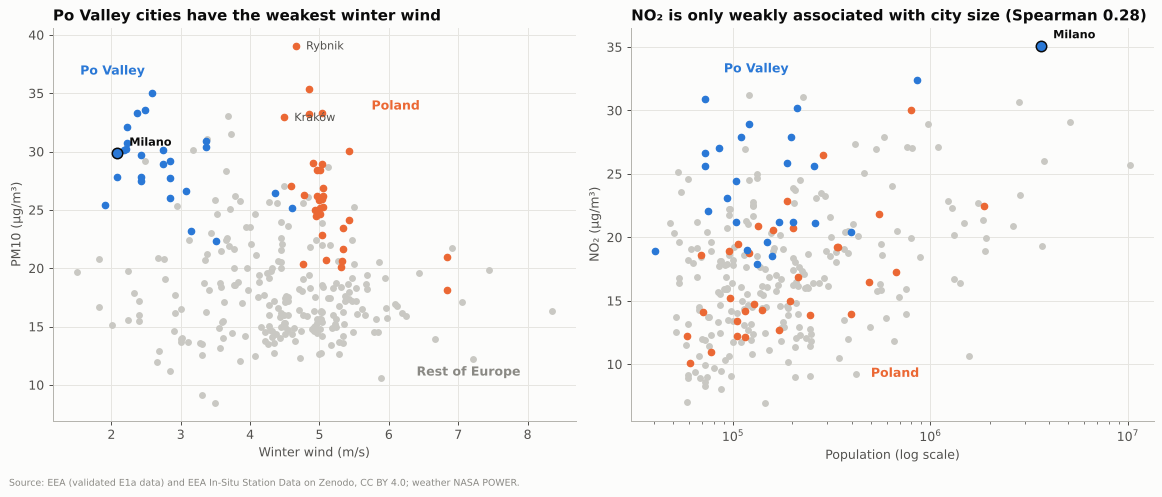

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
panels = [(axes[0], "wind_winter", "pm10_mean"), (axes[1], "population", "no2_mean")]

for ax, x_var, y_var in panels:
    for g in ["Rest of Europe", "Poland", "Po Valley"]:          # grey first, so coloured dots stay on top
        t = cities[cities["group"] == g]
        ax.scatter(t[x_var], t[y_var], s=20 if g == "Rest of Europe" else 26, color=GROUP_COLOURS[g],
                   zorder=1 if g == "Rest of Europe" else 2)
    ax.scatter(milan[x_var], milan[y_var], s=70, color=BLUE, edgecolor=INK, linewidth=1.2, zorder=3)
    ax.annotate("Milano", (milan[x_var], milan[y_var]), xytext=(10, 6), textcoords="offset points",
                fontsize=9, color=INK, fontweight="bold")
    ax.set_xlabel(LABELS[x_var] + (" (log scale)" if x_var == "population" else ""))
    ax.set_ylabel(LABELS[y_var])
axes[1].set_xscale("log")

# Direct labels instead of a legend: the name sits next to the data, no going back and forth to a box.
# Positions in data coordinates, chosen by looking at the figure; each text has the colour of its group.
axes[0].text(1.55, 36.6, "Po Valley", color=BLUE, fontsize=10, fontweight="bold")
axes[0].text(5.75, 33.6, "Poland", color=GROUP_COLOURS["Poland"], fontsize=10, fontweight="bold")
axes[0].text(6.4, 10.8, "Rest of Europe", color=MUTED, fontsize=10, fontweight="bold")
axes[1].text(9.0e4, 33.0, "Po Valley", color=BLUE, fontsize=10, fontweight="bold")
axes[1].text(5.0e5, 9.0, "Poland", color=GROUP_COLOURS["Poland"], fontsize=10, fontweight="bold")

for name in ["Rybnik", "Kraków"]:
    row = cities[cities["city"] == name].iloc[0]
    axes[0].annotate(name, (row["wind_winter"], row["pm10_mean"]), xytext=(8, -3),
                     textcoords="offset points", fontsize=9, color=INK_2)

axes[0].set_title("Po Valley cities have the weakest winter wind")
axes[1].set_title(f"NO₂ is only weakly associated with city size (Spearman {sp('no2_mean', 'population'):.2f})")
fig.tight_layout(rect=(0, 0.03, 1, 1))
source(fig)
fig.savefig("../figures/A3_wind_population.png", bbox_inches="tight")

print("Spearman PM10 - winter wind:", sp("pm10_mean", "wind_winter"))
print("Spearman NO2 - population:", sp("no2_mean", "population"))


**What we see.**
- Across all 284 cities winter wind and PM10 are only weakly associated (Spearman −0.16): the Polish cities have high PM10 with normal wind.
- But the Po Valley cities form a compact group at the **far left**: the weakest winter wind in the dataset (Milan about 2 m/s, against a European median of about 4.5) and high PM10. It is a first hint that in the Po Valley the weather matters more, while in Poland something else is at work, probably a local source. Block C tests the weather part with a model.
- NO₂ is only weakly associated with city size (Spearman 0.28): population is a rough measure, defined differently in each country (see the open questions). Milan is at the top: large **and** with weak wind.
- The Polish cities (orange) have normal or even strong winter wind and still high PM10: not stagnant air. A strong local source, such as coal heating, is the likely explanation, but our data do not measure sources.

> ✅ **CHECKPOINT 6 — Po Valley defined.** 25 cities (written rule), 17 of the 30 cities over the PM10 limit. Two kinds of smog: Po Valley = weak wind; Poland = high PM10 with normal wind (likely a local source).

### 6.2 The three groups compared: notched boxplots

To compare groups we use a **boxplot** (median, box = middle 50% of the cities, whiskers to 1.5 × IQR) with a **notch** (about a 95% interval for the median) and **every city drawn on top** as a dot, because a boxplot alone cannot show gaps or two peaks. If two notches do not overlap, that is evidence that the medians differ; if they overlap, it is *not* evidence that they are equal.

Same colours as everywhere else. No asterisks on the figure: the test and the size of each difference are in the table below it (Kruskal–Wallis, a rank test for more than two groups, with the difference of medians as effect size, because a small p-value says nothing about how big a difference is).

**What the test can and cannot say.** We chose the three groups *after* seeing where the hot spots are (maps, A0). A test on groups chosen this way cannot confirm anything: the p-values are small by construction (circular reasoning). Here Kruskal–Wallis and the differences of medians only *describe* how far apart the groups are. The confirmatory part of the project is in blocks B and C, which do not use these groups to build their results.

,median Po Valley,median Poland,median Rest of Europe,Po Valley − rest,Poland − rest,Kruskal–Wallis p
variable,,,,,,
PM10 (µg/m³),29.23,25.90,17.07,12.16,8.83,1.1e-23
NO₂ (µg/m³),24.45,16.69,16.45,8.00,0.24,1.7e-08
Winter wind (m/s),2.59,5.02,4.48,-1.89,0.53,6.5e-14


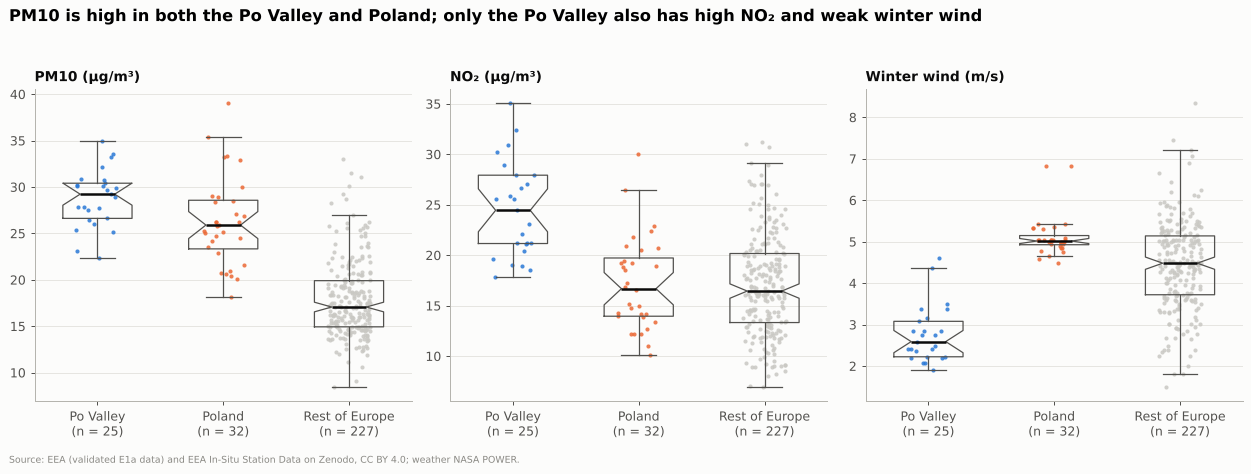

In [23]:
from scipy.stats import kruskal

BOX_VARS = ["pm10_mean", "no2_mean", "wind_winter"]
rng = np.random.default_rng(0)                      # fixed seed: the jitter is the same at every run

fig, axes = plt.subplots(1, 3, figsize=(14, 5.2))
for ax, var in zip(axes, BOX_VARS):
    data = [cities.loc[cities["group"] == g, var] for g in GROUP_ORDER]
    for k, (g, values) in enumerate(zip(GROUP_ORDER, data), start=1):      # the cities, as dots
        ax.scatter(k + rng.uniform(-0.17, 0.17, len(values)), values, s=11, color=GROUP_COLOURS[g],
                   alpha=0.85, linewidth=0, zorder=1)
    ax.boxplot(data, notch=True, widths=0.55, showfliers=False, zorder=2,      # the summary, on top
               boxprops=dict(color=INK_2), whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2),
               medianprops=dict(color=INK, linewidth=2))
    ax.set_xticks([1, 2, 3], [f"{g}\n(n = {len(v)})" for g, v in zip(GROUP_ORDER, data)])
    ax.set_title(LABELS[var], fontsize=11)
    ax.grid(axis="x", visible=False)

fig.suptitle("PM10 is high in both the Po Valley and Poland; only the Po Valley also has high NO₂ and weak winter wind",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 0.94))
source(fig)
fig.savefig("../figures/A6_groups_boxplots.png", bbox_inches="tight")

# The test and the effect sizes, in a table (not as stars on the figure)
rows = []
for var in BOX_VARS:
    data = [cities.loc[cities["group"] == g, var] for g in GROUP_ORDER]
    medians = {g: v.median() for g, v in zip(GROUP_ORDER, data)}
    rows.append({"variable": LABELS[var], **{f"median {g}": medians[g] for g in GROUP_ORDER},
                 "Po Valley − rest": medians["Po Valley"] - medians["Rest of Europe"],
                 "Poland − rest": medians["Poland"] - medians["Rest of Europe"],
                 "Kruskal–Wallis p": f"{kruskal(*data).pvalue:.1e}"})      # p as text: with 2 decimals it would print 0.00
show(pd.DataFrame(rows).set_index("variable"), 2)

**What we see.** PM10: both groups are far above the rest (medians about 29 and 26 µg/m³ against 17). NO₂: the Po Valley is higher (about 24 against 16), Poland is like the rest of Europe. Winter wind: the Po Valley has about half the wind of the others (2.6 against 4.5–5 m/s), Poland has slightly *more* wind than the rest. The notches of the Po Valley do not overlap with the others in any panel.

Two things to know before showing it. With 25 cities the notch of the Po Valley is wider than the box and folds back beyond it (a known effect of small samples). The Polish winter wind is almost the same in all 32 cities (4.5–5.4 m/s): part of this is real (flat land), part may come from the weather data, which are averages over cells of about 50 km.

This is the "two kinds of smog" of the project in one figure. It is a description of groups we chose, not a proof of the causes: blocks B and C test it.

### 6.3 Opening figure: Milan among the 284 cities

The figure for the first slide. Every label is joined to its dot by a thin line, and the name is looked up in the table, so a wrong name stops the notebook instead of landing on the wrong dot.

Reference lines: the new EU annual limits from 2030 (Directive 2024/2881), 20 µg/m³ for both PM10 and NO₂. They are drawn as **references**: our values are 2016–2023 means of background stations, so a city to the right of a line is not a legal breach.

20 cities have more PM10 than Milan; 16 of them in the Po Valley or Poland


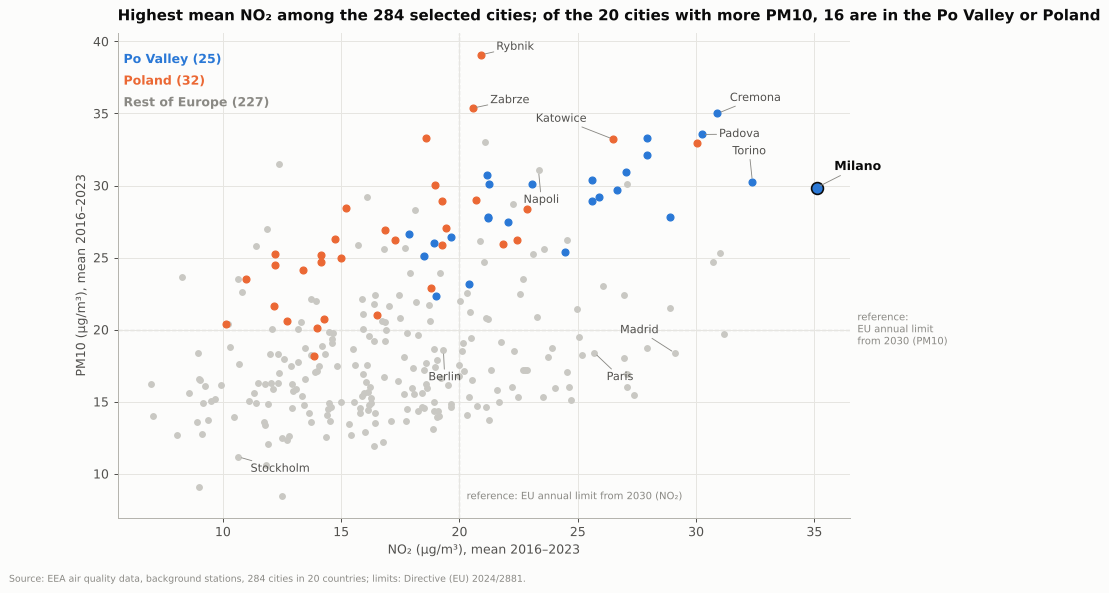

In [24]:
# City -> (dx, dy): position of the label relative to the dot, in points, chosen by looking at the figure
LABELLED = {
    "Milano (greater city)": (14, 14), "Torino": (-16, 22), "Cremona": (10, 10), "Padova": (14, -2),
    "Rybnik": (12, 4), "Zabrze": (14, 4), "Katowice": (-62, 14),
    "Napoli (greater city)": (-12, -26), "Paris (greater city)": (10, -22), "Madrid": (-44, 16),
    "Berlin": (-12, -24), "Stockholm (greater city)": (10, -12),
}
SHORT = lambda name: name.replace(" (greater city)", "")

fig, ax = plt.subplots(figsize=(10.5, 7))
for g in ["Rest of Europe", "Poland", "Po Valley"]:
    t = cities[cities["group"] == g]
    ax.scatter(t["no2_mean"], t["pm10_mean"], s=20 if g == "Rest of Europe" else 30, color=GROUP_COLOURS[g],
               zorder=1 if g == "Rest of Europe" else 2)
ax.scatter(milan["no2_mean"], milan["pm10_mean"], s=90, color=BLUE, edgecolor=INK, linewidth=1.3, zorder=3)

for name, (dx, dy) in LABELLED.items():
    row = cities.loc[cities["city"] == name].iloc[0]        # IndexError here = the name is not in the table
    bold = name.startswith("Milano")
    ax.annotate(SHORT(name), (row["no2_mean"], row["pm10_mean"]), xytext=(dx, dy), textcoords="offset points",
                fontsize=10 if bold else 9, fontweight="bold" if bold else "normal", color=INK if bold else INK_2,
                arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.7, shrinkA=0, shrinkB=3))

ax.axhline(20, color=MUTED, linewidth=0.9, linestyle="--", zorder=0)
ax.axvline(20, color=MUTED, linewidth=0.9, linestyle="--", zorder=0)
ax.text(1.01, 20, "reference:\nEU annual limit\nfrom 2030 (PM10)", transform=ax.get_yaxis_transform(),
        fontsize=8, color=MUTED, va="center")          # in the right margin, away from the dots
ax.text(20.3, cities["pm10_mean"].min() - 0.4, "reference: EU annual limit from 2030 (NO₂)", fontsize=8, color=MUTED, va="bottom")

n_group = cities["group"].value_counts()
ax.text(5.8, 38.5, f"Po Valley ({n_group['Po Valley']})", color=BLUE, fontsize=10, fontweight="bold")
ax.text(5.8, 37.0, f"Poland ({n_group['Poland']})", color=GROUP_COLOURS["Poland"], fontsize=10, fontweight="bold")
ax.text(5.8, 35.5, f"Rest of Europe ({n_group['Rest of Europe']})", color=MUTED, fontsize=10, fontweight="bold")

ax.set_xlabel(LABELS["no2_mean"] + ", mean 2016–2023")
ax.set_ylabel(LABELS["pm10_mean"] + ", mean 2016–2023")
n_above = int((cities["pm10_mean"] > milan["pm10_mean"]).sum())
n_above_groups = int(((cities["pm10_mean"] > milan["pm10_mean"]) & (cities["group"] != "Rest of Europe")).sum())
ax.set_title(f"Highest mean NO₂ among the 284 selected cities; of the {n_above} cities with more PM10, "
             f"{n_above_groups} are in the Po Valley or Poland", pad=10)
source(fig, "Source: EEA air quality data, background stations, 284 cities in 20 countries; "
            "limits: Directive (EU) 2024/2881.")
fig.savefig("../figures/A0_milan_vs_europe.png", bbox_inches="tight")
print(n_above, "cities have more PM10 than Milan;", n_above_groups, "of them in the Po Valley or Poland")

## 7. Milan through the year

The monthly weather table (`data/interim/weather_cities_monthly.csv`, NASA POWER) lets us compare Milan with all the other cities, month by month. Blue line: Milan. Grey line and band: median of all cities and the middle 50% of cities. The mixing layer is computed as in notebook 01: (surface pressure − pressure at the top of the boundary layer) × 10 × 8.5 m.

Cities in the monthly weather table: 284


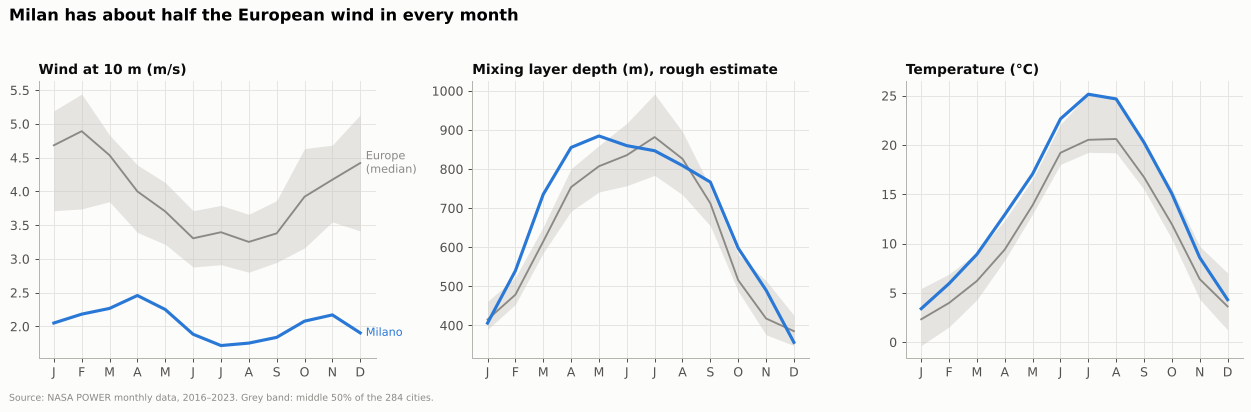

In [25]:
monthly = pd.read_csv("../data/interim/weather_cities_monthly.csv")
# The weather file also has the 5 cities removed in notebook 01: keep only the 284 of the final table
monthly = monthly.merge(cities[["country", "city"]], on=["country", "city"])
print("Cities in the monthly weather table:", monthly[["country", "city"]].drop_duplicates().shape[0])
monthly = monthly.pivot_table(index=["country", "city", "year", "month"], columns="variable", values="value").reset_index()
monthly["mixing_layer"] = (monthly["PS"] - monthly["PBLTOP"]) * 10 * 8.5

# Mean over the 8 years, for every city and month
by_month = monthly.groupby(["country", "city", "month"])[["WS10M", "mixing_layer", "T2M"]].mean().reset_index()
milan_months = by_month[by_month["city"] == milan["city"]].set_index("month")
europe = by_month.groupby("month")[["WS10M", "mixing_layer", "T2M"]].quantile([0.25, 0.5, 0.75]).unstack()

MONTHS = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, var, title in [(axes[0], "WS10M", "Wind at 10 m (m/s)"),
                       (axes[1], "mixing_layer", "Mixing layer depth (m), rough estimate"),
                       (axes[2], "T2M", "Temperature (°C)")]:
    ax.fill_between(range(1, 13), europe[(var, 0.25)], europe[(var, 0.75)], color=GREY, alpha=0.45, linewidth=0)
    ax.plot(range(1, 13), europe[(var, 0.5)], color=MUTED, linewidth=1.5)
    ax.plot(range(1, 13), milan_months[var], color=BLUE, linewidth=2.5)
    ax.set_xticks(range(1, 13), MONTHS)
    ax.set_title(title, fontsize=11)
axes[0].text(12.2, milan_months.loc[12, "WS10M"], "Milano", color=BLUE, fontsize=9, va="center")
axes[0].text(12.2, europe.loc[12, ("WS10M", 0.5)], "Europe\n(median)", color=MUTED, fontsize=9, va="center")
fig.suptitle("Milan has about half the European wind in every month", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
source(fig, "Source: NASA POWER monthly data, 2016–2023. Grey band: middle 50% of the 284 cities.")
fig.savefig("../figures/A4_milan_through_the_year.png", bbox_inches="tight")

**What we see.**
- **Wind**: Milan is below the whole grey band in every month, at about half the European median. The air over Milan is always stiller than almost anywhere else in our sample.
- **Mixing layer**: in winter it is shallow everywhere (about 400 m) and Milan follows the European median, so with our estimate this variable does not single Milan out: consistent with section 5.3.
- **Temperature**: Milan is warmer than the median in summer and about average in winter.

So the "stagnant air" of the Po Valley shows up in the data mainly as **lack of wind**.

> ✅ **CHECKPOINT 7 — Milan profiled.** About half the European wind all year round (from 43% of the median in December to 61% in April–May); mixing layer not distinctive with our data.

## 8. What we pass on to blocks B and C

In [26]:
print("FOR BLOCK B (clustering on the pollution variables)")
print("- PM2.5 and PM2.5/PM10 missing in", no_pm25.sum(), "cities, including Rybnik and Zabrze (highest PM10):")
print("  cluster the 284 cities without the two PM2.5 columns; check with the 244 complete cities.")
print("- Skewed pollution variables, consider a logarithm:",
      [v for v in POLLUTION if abs(cities[v].skew()) > 1])
print("- Two different hot spots: Po Valley (PM10 and NO2) and Poland (PM10 high, NO2 like the rest of Europe).")
print()
print("FOR BLOCK C (classification from weather and geography)")
print("- Population is complete (12 values filled from official sources in notebook 01): take the log.")
print("- Skewed external variables:", [v for v in EXTERNAL if abs(cities[v].skew()) > 1])
print("- Do not use the yearly mixing layer; the winter one only as a weak candidate; winter wind = stagnation.")
print("- Of the", cities["exceeds_pm10_limit"].sum(), "cities over the limit,",
      cities.loc[cities["exceeds_pm10_limit"], "po_valley"].sum(), "are in the Po Valley.")

FOR BLOCK B (clustering on the pollution variables)
- PM2.5 and PM2.5/PM10 missing in 40 cities, including Rybnik and Zabrze (highest PM10):
  cluster the 284 cities without the two PM2.5 columns; check with the 244 complete cities.
- Skewed pollution variables, consider a logarithm: ['pm25_mean', 'pm10_days_above_50', 'pm10_winter_summer']
- Two different hot spots: Po Valley (PM10 and NO2) and Poland (PM10 high, NO2 like the rest of Europe).

FOR BLOCK C (classification from weather and geography)
- Population is complete (12 values filled from official sources in notebook 01): take the log.
- Skewed external variables: ['rain_mm_day', 'mixing_layer_winter_m', 'altitude', 'population']
- Do not use the yearly mixing layer; the winter one only as a weak candidate; winter wind = stagnation.
- Of the 30 cities over the limit, 17 are in the Po Valley.


### Open questions (to discuss in the group)

- **Population is a rough measure of size.** Each country defines "city" differently (municipality, metropolitan area, "greater city"): Paris counts 10 million, Lyon 1.3 million (metropolitan area), Milan 3.6 million. Use it on a log scale and do not read small differences.
- **Ozone peaks, not summer ozone.** `o3_peaks` is the 93rd percentile of the daily maximum 8-hour mean over the whole year (the EU indicator, see notebook 01). Its high values fall in the sunny months, but no month is left out of the computation.
- **Coordinates as predictors in block C.** Latitude and longitude can "learn" the Po Valley without any weather. Block C should run its models with and without them and compare.
- **Nearby cities are not independent.** Cities of the Po Valley share the same air: in a random cross-validation a city can be predicted from its neighbours in the training set, which makes the model look better than it is. A fairer test: cross-validation grouped by country or region. A good point to raise at the exam.
- **Correlated predictors** (wind and winter wind, temperature and frost days): block C should read importances with care, or keep only one of each pair.
- **Uneven sample.** Italy, Germany and France are 59% of the cities; the United Kingdom is missing (no PM10 reported after 2019). Results describe these 20 countries, not all of Europe.
- **Weather resolution.** NASA POWER gives monthly means on cells of about 50 km. The winter wind is almost the same in all 32 Polish cities (4.5–5.4 m/s, figure A6): partly real (flat land), partly the smoothing of the data. The weather of nearby cities is close also for this reason; to be named as a limit.
- **2020.** The lockdown year is inside the 2016–2023 means. It lowers NO₂ in every city a little; it could be an extra analysis (idea already in the project page).
- **The PM10 target is our indicator**, a mean over stations and years, not the legal assessment (which is per station and per year).

## 9. The final figures, each in four lines

Every figure is described in four lines (question, encodings, colour scale, source): if they cannot be written, the figure is not finished. Each is also labelled exploratory, confirmatory or for presentation. None of the figures of this notebook is confirmatory: block A describes, blocks B and C test.

The table is built with pandas and `show()`, like the other tables of the project, so that it stays aligned to the left in VS Code.

In [27]:
FIGURE_SPECS = pd.DataFrame([
    ["A0 Milan among the cities", "Where does Milan stand for the two main pollutants?",
     "x = NO₂ mean, y = PM10 mean, one dot per city; dashed lines = EU 2030 annual limits, as references",
     "3 groups (blue Po Valley, orange Poland, grey rest): categorical, few colours, grey as context",
     "EEA, 284 cities, 2016–2023", "Presentation"],
    ["A1 Maps", "Where in Europe is pollution highest?",
     "Position = city on an equal-area map (EPSG:3035); colour = class of PM10 / NO₂",
     "ColorBrewer YlOrRd, classed: breaks at WHO 2021 and EU 2030 values, so a dot can be read against the legend",
     "EEA + Natural Earth, 284 cities", "Presentation"],
    ["A2 Correlations", "Which weather and geography variables move with which pollutant?",
     "Rows = external variables, columns = pollution variables; colour and number = Spearman ρ",
     "Diverging PuOr: zero has a meaning (no relation), and neither sign is 'good'",
     "EEA + NASA POWER, 284 cities", "Exploratory"],
    ["A3 Wind and size", "Is PM10 related to winter wind, and NO₂ to city size?",
     "x = winter wind / population (log), y = PM10 / NO₂, one dot per city",
     "Same 3 groups as A0", "EEA + NASA POWER + Eurostat, 284 cities", "Exploratory"],
    ["A4 Milan through the year", "Is Milan's air stiller than the rest all year, or only in winter?",
     "x = month; y = wind, mixing layer, temperature; line = Milan, grey line and band = median and middle 50%",
     "One colour for Milan, grey for context", "NASA POWER, 284 cities, 2016–2023", "Presentation (wind panel)"],
    ["A5 Milan's percentiles", "In which variables is Milan extreme?",
     "One row per variable; x = Milan's percentile rank 0–100 (284 cities, 244 for PM2.5); grey band = middle 50%",
     "One colour (Milan)", "All sources, 284 cities", "Presentation"],
    ["A6 Three groups", "Do the Po Valley and Poland differ from the rest, and in the same way?",
     "x = group, y = PM10 / NO₂ / winter wind; notched boxplot + every city as a dot",
     "Same 3 groups", "EEA + NASA POWER, 25 / 32 / 227 cities", "Descriptive / Presentation"],
], columns=["Figure", "Question", "Encodings", "Colour, and why that scale", "Source and n", "Task"])
show(FIGURE_SPECS.set_index("Figure"))


,Question,Encodings,"Colour, and why that scale",Source and n,Task
Figure,,,,,
A0 Milan among the cities,Where does Milan stand for the two main pollutants?,"x = NO₂ mean, y = PM10 mean, one dot per city; dashed lines = EU 2030 annual limits, as references","3 groups (blue Po Valley, orange Poland, grey rest): categorical, few colours, grey as context","EEA, 284 cities, 2016–2023",Presentation
A1 Maps,Where in Europe is pollution highest?,Position = city on an equal-area map (EPSG:3035); colour = class of PM10 / NO₂,"ColorBrewer YlOrRd, classed: breaks at WHO 2021 and EU 2030 values, so a dot can be read against the legend","EEA + Natural Earth, 284 cities",Presentation
A2 Correlations,Which weather and geography variables move with which pollutant?,"Rows = external variables, columns = pollution variables; colour and number = Spearman ρ","Diverging PuOr: zero has a meaning (no relation), and neither sign is 'good'","EEA + NASA POWER, 284 cities",Exploratory
A3 Wind and size,"Is PM10 related to winter wind, and NO₂ to city size?","x = winter wind / population (log), y = PM10 / NO₂, one dot per city",Same 3 groups as A0,"EEA + NASA POWER + Eurostat, 284 cities",Exploratory
A4 Milan through the year,"Is Milan's air stiller than the rest all year, or only in winter?","x = month; y = wind, mixing layer, temperature; line = Milan, grey line and band = median and middle 50%","One colour for Milan, grey for context","NASA POWER, 284 cities, 2016–2023",Presentation (wind panel)
A5 Milan's percentiles,In which variables is Milan extreme?,"One row per variable; x = Milan's percentile rank 0–100 (284 cities, 244 for PM2.5); grey band = middle 50%",One colour (Milan),"All sources, 284 cities",Presentation
A6 Three groups,"Do the Po Valley and Poland differ from the rest, and in the same way?","x = group, y = PM10 / NO₂ / winter wind; notched boxplot + every city as a dot",Same 3 groups,"EEA + NASA POWER, 25 / 32 / 227 cities",Descriptive / Presentation
